# Smart Helmet — Crash/Impact Detection (Anomaly Model)

This notebook documents how we **built**, **trained**, and **tested** an **unsupervised anomaly-detection model** for detecting unusual riding patterns that may indicate a crash or dangerous event.

**Core idea:** we turn raw telemetry (IMU + speed) into rolling-window features, then train an **Isolation Forest** to learn what “normal riding” looks like. Windows that look very different get low anomaly scores.

> If you’re opening this in VS Code: you can run it on a local/remote Jupyter server. The model artifacts saved at the end are the same ones your backend can load for real-time scoring.


## 0) Setup

### Libraries
We use:
- `pandas`, `numpy` for data handling
- `matplotlib` for charts
- `scikit-learn` for the model (`StandardScaler` + `IsolationForest`)
- `joblib` to save the trained pipeline

If something is missing in your environment, install it (conda recommended):
```bash
conda install -y numpy pandas matplotlib scikit-learn joblib
```


In [28]:

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
import joblib



## 1) Load the dataset

Your cleaned telemetry file is expected to have these columns (or very similar):
- `ts` (seconds), `timestamp`
- IMU: `imu_ax`, `imu_ay`, `imu_az`, `imu_gx`, `imu_gy`, `imu_gz`
- speed: `velocity_kmh`

We’ll search a few common locations and load the first one found.


In [29]:
df = pd.read_csv("./data/driving_clean.csv")
df.head()

,ts,device_id,helmet_on,timestamp,heart_rate_ok,heart_rate_ir,heart_rate_red,heart_rate_finger,heart_rate_hr,heart_rate_spo2,...,imu_gx,imu_gy,imu_gz,gps_ok,gps_lat,gps_lng,gps_alt,gps_sats,gps_lock,velocity_kmh
0,1208,HELMET_001,True,2026-01-05 00:47:35.495364,True,30801,17497,True,94.0,98.0,...,8.60,0.18,-0.97,True,33.558951,35.386578,70.5,8.0,True,0.0
1,1209,HELMET_001,True,2026-01-05 00:47:36.542355,True,30956,17530,True,93.0,98.0,...,5.98,3.66,-20.08,True,33.558951,35.386577,70.4,8.0,True,0.0
2,1210,HELMET_001,True,2026-01-05 00:47:37.577620,True,30973,17549,True,91.0,99.0,...,11.53,18.73,9.33,True,33.558952,35.386575,70.2,8.0,True,0.0
3,1211,HELMET_001,True,2026-01-05 00:47:38.654086,True,30971,17529,True,94.0,98.0,...,0.36,-5.98,15.93,True,33.558952,35.386575,70.1,8.0,True,0.0
4,1212,HELMET_001,True,2026-01-05 00:47:39.742161,True,31092,17579,True,93.0,99.0,...,35.46,-3.41,76.66,True,33.558947,35.386575,70.2,8.0,True,0.0


### Quick sanity checks

In [30]:
print("Shape:", df.shape)
print("Columns:", df.columns)

Shape: (1363, 25)
Columns: Index(['ts', 'device_id', 'helmet_on', 'timestamp', 'heart_rate_ok',
       'heart_rate_ir', 'heart_rate_red', 'heart_rate_finger', 'heart_rate_hr',
       'heart_rate_spo2', 'imu_ok', 'imu_sleep', 'imu_ax', 'imu_ay', 'imu_az',
       'imu_gx', 'imu_gy', 'imu_gz', 'gps_ok', 'gps_lat', 'gps_lng', 'gps_alt',
       'gps_sats', 'gps_lock', 'velocity_kmh'],
      dtype='object')


### Basic distributions
These quick charts help confirm the data looks realistic (no crazy spikes everywhere).

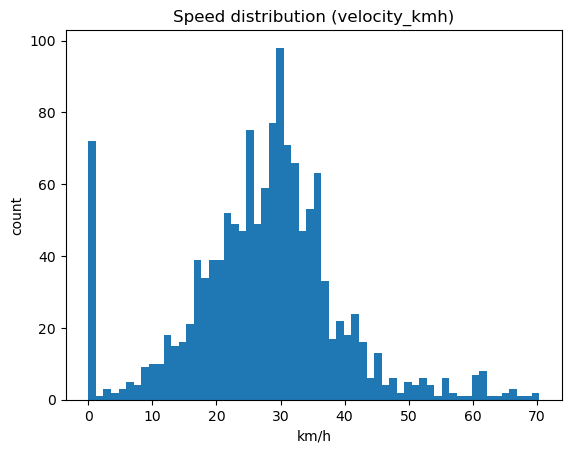

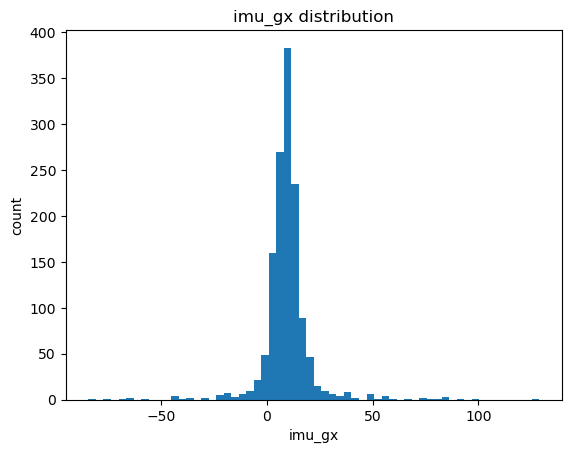

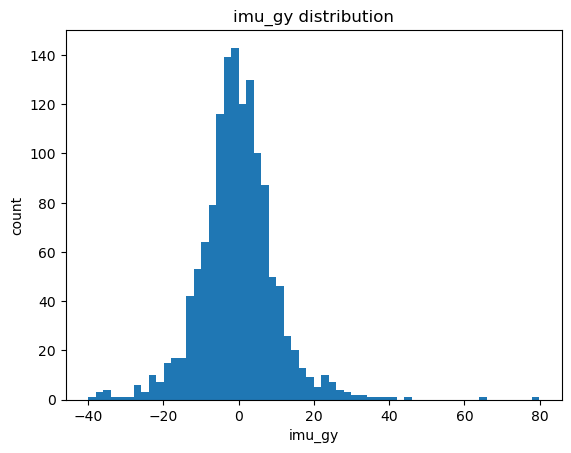

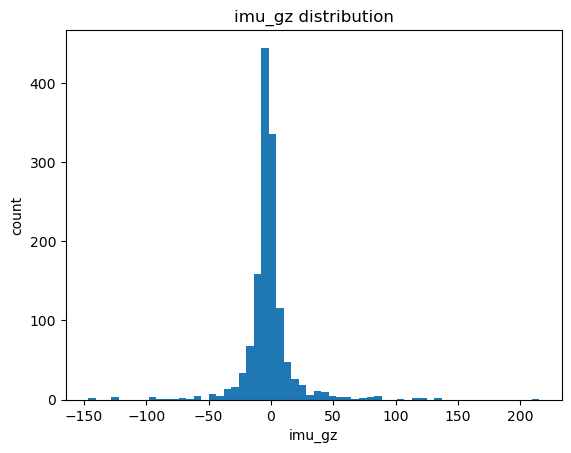

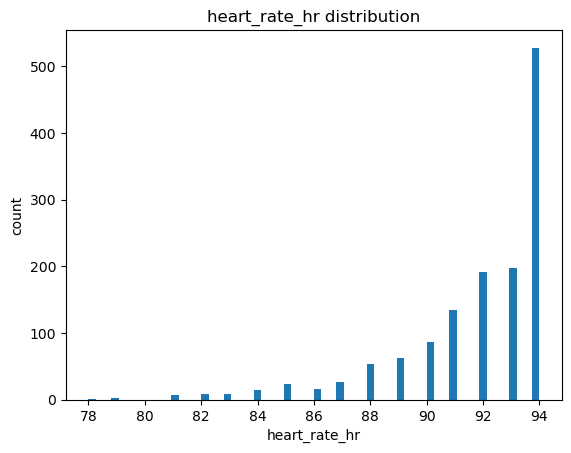

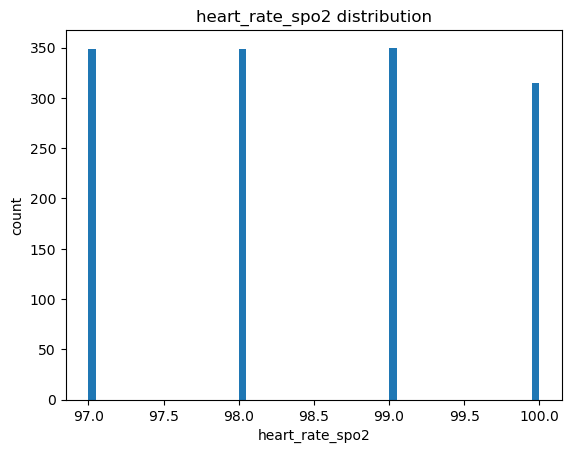

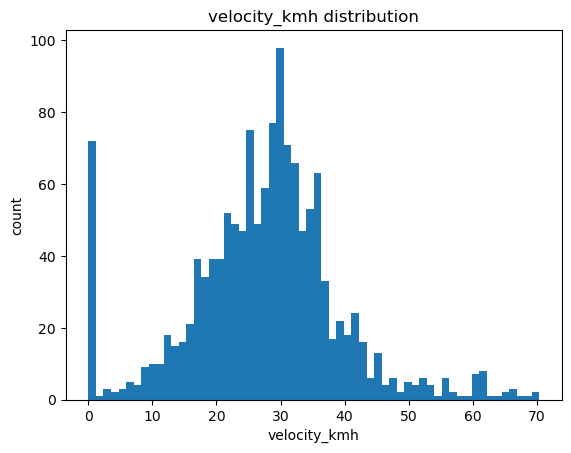

In [31]:

# Speed distribution
if "velocity_kmh" in df.columns:
    plt.figure()
    df["velocity_kmh"].plot(kind="hist", bins=60)
    plt.title("Speed distribution (velocity_kmh)")
    plt.xlabel("km/h")
    plt.ylabel("count")
    plt.show()

for col in ["imu_gx", "imu_gy", "imu_gz","heart_rate_hr","heart_rate_spo2","velocity_kmh"]:
    plt.figure()
    pd.to_numeric(df[col]).plot(kind="hist", bins=60)
    plt.title(f"{col} distribution")
    plt.xlabel(col)
    plt.ylabel("count")
    plt.show()


## 2) Feature engineering (rolling windows)

Raw sensor rows are noisy. Instead of scoring each row, we score **short windows** (example: 10 seconds).

### Features we use
- **Acceleration magnitude**: `sqrt(ax² + ay² + az²)`
- **Gyro magnitude**: `sqrt(gx² + gy² + gz²)`
- **Jerk proxy**: `abs(diff(acc_mag))`

Then we compute rolling stats (mean/std/min/max) over a fixed window.

Why this matters: crashes/impacts tend to show up as unusual patterns over a short time span, not just one sample.


In [32]:

WINDOW_SAMPLES = 10 #10 rows 

def build_features(df: pd.DataFrame, window: int) -> pd.DataFrame:
    df = df.copy()

    # sort by time which is important for the rolling windows
    if "ts" in df.columns:
        df = df.sort_values("ts").reset_index(drop=True)

    # keep original row index so we can inspect windows later
    df["row_idx"] = np.arange(len(df), dtype=int)

    # making sure all columns are numeric
    df["speed"] = pd.to_numeric(df.get("velocity_kmh"))
    for c in ["imu_ax", "imu_ay", "imu_az", "imu_gx", "imu_gy", "imu_gz"]:
        df[c] = pd.to_numeric(df.get(c))

    # calculating magnitudes
    df["acc_mag"] = np.sqrt(df["imu_ax"]**2 + df["imu_ay"]**2 + df["imu_az"]**2)
    df["gyro_mag"] = np.sqrt(df["imu_gx"]**2 + df["imu_gy"]**2 + df["imu_gz"]**2)

    # jerk proxy
    df["jerk"] = df["acc_mag"].diff().abs()

    r_acc = df["acc_mag"].rolling(window, min_periods=window)
    r_gyro = df["gyro_mag"].rolling(window, min_periods=window)
    r_speed = df["speed"].rolling(window, min_periods=window)
    r_jerk = df["jerk"].rolling(window, min_periods=window)

    feat = pd.DataFrame({
        "ts": df.get("ts"),
        "timestamp": df.get("timestamp"),
        "row_idx": df["row_idx"], 

        # acc magnitude
        "acc_mean": r_acc.mean(),
        "acc_std": r_acc.std(ddof=0),
        "acc_max": r_acc.max(),
        "acc_min": r_acc.min(),

        # jerk
        "jerk_mean": r_jerk.mean(),
        "jerk_max": r_jerk.max(),

        # gyroo magnitude
        "gyro_mean": r_gyro.mean(),
        "gyro_std": r_gyro.std(ddof=0),
        "gyro_max": r_gyro.max(),

        # speeed
        "speed_mean": r_speed.mean(),
        "speed_max": r_speed.max(),
        "speed_delta": df["speed"] - df["speed"].shift(window - 1),
    })

    feature_cols = [c for c in feat.columns if c not in ("ts", "timestamp", "row_idx")]
    feat = feat.dropna(subset=feature_cols)
    return feat.reset_index(drop=True)

feat = build_features(df, WINDOW_SAMPLES)

print("Feature windows:", len(feat))
feat.head()


Feature windows: 1353


,ts,timestamp,row_idx,acc_mean,acc_std,acc_max,acc_min,jerk_mean,jerk_max,gyro_mean,gyro_std,gyro_max,speed_mean,speed_max,speed_delta
0,1218,2026-01-05 00:47:48.833299,10,1.038298,0.060392,1.107204,0.920598,0.078096,0.18022,25.385040,21.477449,84.532806,4.639260,13.63072,13.63072
1,1220,2026-01-05 00:47:49.020896,11,1.035018,0.059555,1.107204,0.920598,0.081952,0.18022,25.032410,21.570883,84.532806,6.213460,15.74200,15.74200
2,1221,2026-01-05 00:47:49.029825,12,1.036593,0.059450,1.107204,0.920598,0.077926,0.18022,25.365013,21.576368,84.532806,7.854332,16.40872,16.40872
3,1222,2026-01-05 00:47:50.335510,13,1.029205,0.055648,1.107204,0.920598,0.071791,0.18022,28.115909,22.084606,84.532806,9.408160,16.40872,15.53828
4,1223,2026-01-05 00:47:51.084703,14,1.043357,0.042723,1.107204,0.962912,0.057560,0.18022,23.776618,12.945122,44.528205,10.521212,16.40872,11.13052


## 3) Train/test split (by time)

Even though this is unsupervised, we still split by time:
- Train on the **earlier** part of the ride
- Test on the **later** part

Why: it’s a practical sanity check that the model isn’t just memorizing one segment.


In [33]:
# sort windows by time before split
feat = feat.sort_values(["ts"]).reset_index(drop=True)

feature_cols = [c for c in feat.columns if c not in ("ts", "timestamp", "row_idx")]
X = feat[feature_cols]

# shuffle=False keeps time-based testing
X_train, X_test, feat_train, feat_test = train_test_split(
    X, feat,
    test_size=0.3,
    shuffle=False
)

print("Train windows:", len(feat_train))
print("Test windows:", len(feat_test))

Train windows: 947
Test windows: 406


## 4) Model training (Isolation Forest)

Isolation Forest is good for anomaly detection because it tries to isolate unusual points using random splits.

- We scale features with `StandardScaler` because features have different ranges.
- `contamination` is a training-time hint (not your final alert rate).


In [34]:

CONTAMINATION = 0.01  # training-time hint, Isolation Forest needs some idea of how “rare” anomalies

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("iforest", IsolationForest(
        n_estimators=400,
        contamination=CONTAMINATION,
        random_state=42,
    )),
])

pipeline.fit(X_train)

# decision_function: higher = more normal; lower = more anomalous
feat_train["anomaly_score"] = pipeline.decision_function(X_train)
feat_test["anomaly_score"] = pipeline.decision_function(X_test)

feat_train[["ts", "timestamp", "anomaly_score"]].head()


,ts,timestamp,anomaly_score
0,1218,2026-01-05 00:47:48.833299,0.141316
1,1220,2026-01-05 00:47:49.020896,0.151336
2,1221,2026-01-05 00:47:49.029825,0.150732
3,1222,2026-01-05 00:47:50.335510,0.150324
4,1223,2026-01-05 00:47:51.084703,0.158605


## 5) Choose a stable threshold (percentile rule)

Instead of hardcoding a score, we pick a threshold from **your own training data** using a percentile.

**Rule used for alerts:**
`anomaly_score < score_threshold` → flagged window


Threshold percentile: 0.5 %
Score threshold: -0.02494832338581036
Flagged in TRAIN: 0.53%
Flagged in TEST : 0.00%


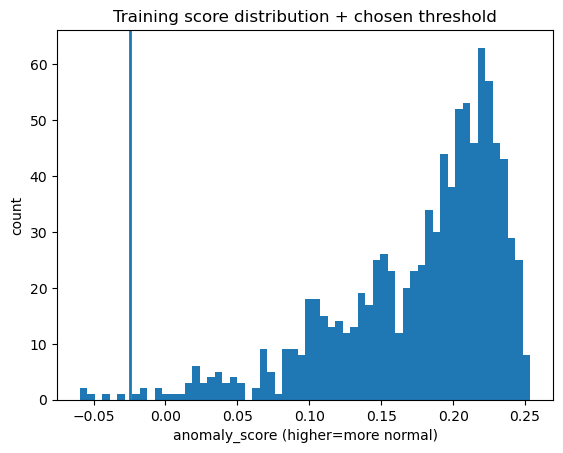

In [35]:

THRESH_PERCENTILE = 0.5  #  very strict (only the most extreme windows are considered anomalies).

score_threshold = float(np.percentile(feat_train["anomaly_score"], THRESH_PERCENTILE))

feat_train["is_anomaly"] = feat_train["anomaly_score"] < score_threshold
feat_test["is_anomaly"] = feat_test["anomaly_score"] < score_threshold

print("Threshold percentile:", THRESH_PERCENTILE, "%")
print("Score threshold:", score_threshold)
print("Flagged in TRAIN:", f"{feat_train['is_anomaly'].mean()*100:.2f}%")
print("Flagged in TEST :", f"{feat_test['is_anomaly'].mean()*100:.2f}%")

plt.figure()
plt.hist(feat_train["anomaly_score"], bins=60)
plt.axvline(score_threshold, linewidth=2)
plt.title("Training score distribution + chosen threshold")
plt.xlabel("anomaly_score (higher=more normal)")
plt.ylabel("count")
plt.show()


## 6) Inspect the most anomalous windows

This is the practical part: we list the lowest-scoring windows and visually inspect what happened in raw telemetry around that time.


In [36]:

top_test = feat_test.nsmallest(15, "anomaly_score")[["ts", "row_idx", "anomaly_score", "is_anomaly"] + feature_cols]
top_test


,ts,row_idx,anomaly_score,is_anomaly,acc_mean,acc_std,acc_max,acc_min,jerk_mean,jerk_max,gyro_mean,gyro_std,gyro_max,speed_mean,speed_max,speed_delta
1272,2870,1282,-0.019644,False,1.077828,0.134936,1.220697,0.768895,0.227915,0.451801,22.464065,15.103932,66.374379,15.636436,16.96432,-0.37040
1270,2867,1280,-0.014282,False,1.041192,0.147914,1.220697,0.768895,0.217005,0.451801,23.495598,15.076079,66.374379,15.923496,17.68660,-1.42604
1271,2869,1281,-0.013953,False,1.036570,0.148436,1.220697,0.768895,0.230180,0.451801,22.601738,15.079905,66.374379,15.766076,17.68660,-2.44464
1273,2871,1283,-0.011551,False,1.056910,0.137739,1.220697,0.768895,0.220263,0.451801,23.913949,14.794167,66.374379,15.671624,17.11248,0.14816
1274,2872,1284,-0.008890,False,1.066276,0.132305,1.220697,0.768895,0.207095,0.451801,22.626231,15.180794,66.374379,15.695700,17.20508,1.88904
1268,2865,1278,-0.005361,False,1.019260,0.146761,1.220697,0.768895,0.213980,0.451801,18.114078,5.645951,27.453446,15.817932,17.68660,0.98156
1269,2866,1279,-0.003507,False,1.032640,0.142984,1.220697,0.768895,0.221833,0.451801,17.865322,5.454311,27.453446,15.923496,17.68660,-0.46300
1275,2873,1285,0.001513,False,1.059481,0.129458,1.220697,0.768895,0.190933,0.451801,22.908398,15.012100,66.374379,15.884604,17.20508,2.11128
1276,2874,1286,0.002959,False,1.044220,0.130975,1.220697,0.768895,0.199399,0.451801,22.959104,14.986316,66.374379,16.084620,17.20508,1.66680
1314,2914,1324,0.038548,False,1.016579,0.089654,1.225112,0.839107,0.089113,0.386006,32.702091,30.462602,120.835361,1.633464,5.42636,-5.42636


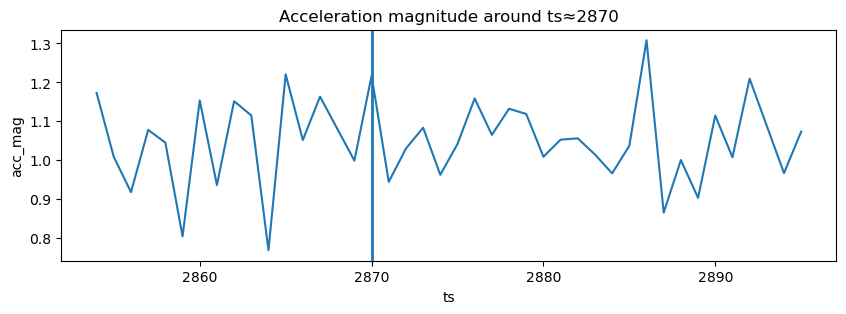

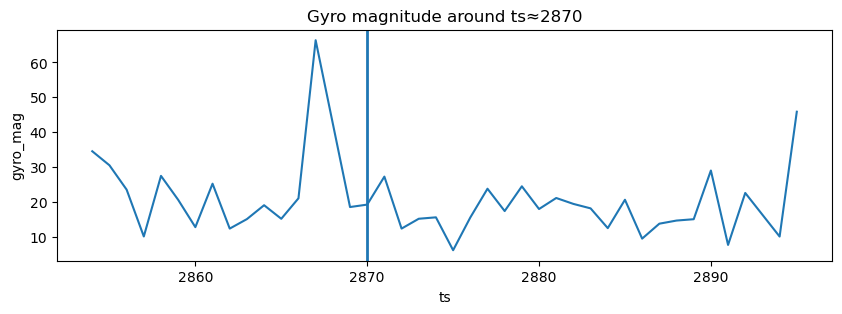

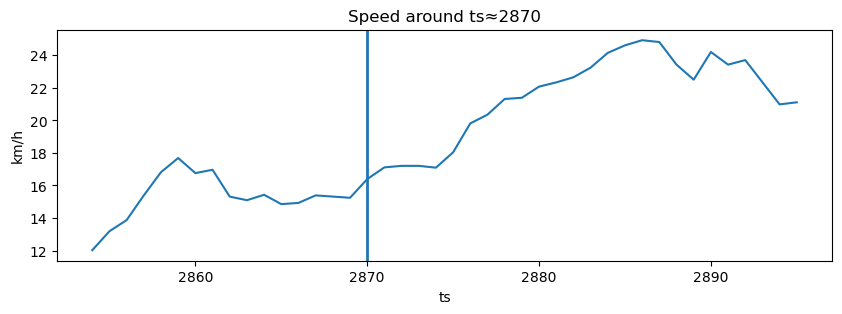

In [37]:

def plot_window_around_ts(df_raw: pd.DataFrame, ts_value: float, window: int = 10, pad: int = 10):
    df_raw = df_raw.sort_values("ts").reset_index(drop=True)
    # find closest ts
    idx = int((df_raw["ts"] - ts_value).abs().idxmin())
    start = max(0, idx - pad)
    end = min(len(df_raw), idx + window + pad)

    chunk = df_raw.iloc[start:end].copy()
    chunk["timestamp"] = pd.to_datetime(chunk.get("timestamp"), errors="coerce")

    # compute magnitudes for plotting
    for c in ["imu_ax", "imu_ay", "imu_az", "imu_gx", "imu_gy", "imu_gz", "velocity_kmh"]:
        if c in chunk.columns:
            chunk[c] = pd.to_numeric(chunk[c], errors="coerce")

    chunk["acc_mag"] = np.sqrt(chunk["imu_ax"]**2 + chunk["imu_ay"]**2 + chunk["imu_az"]**2)
    chunk["gyro_mag"] = np.sqrt(chunk["imu_gx"]**2 + chunk["imu_gy"]**2 + chunk["imu_gz"]**2)

    x = chunk["ts"] if "ts" in chunk.columns else np.arange(len(chunk))

    plt.figure(figsize=(10, 3))
    plt.plot(x, chunk["acc_mag"])
    plt.title(f"Acceleration magnitude around ts≈{ts_value}")
    plt.xlabel("ts")
    plt.ylabel("acc_mag")
    plt.axvline(ts_value, linewidth=2)
    plt.show()

    plt.figure(figsize=(10, 3))
    plt.plot(x, chunk["gyro_mag"])
    plt.title(f"Gyro magnitude around ts≈{ts_value}")
    plt.xlabel("ts")
    plt.ylabel("gyro_mag")
    plt.axvline(ts_value, linewidth=2)
    plt.show()

    plt.figure(figsize=(10, 3))
    plt.plot(x, chunk["velocity_kmh"])
    plt.title(f"Speed around ts≈{ts_value}")
    plt.xlabel("ts")
    plt.ylabel("km/h")
    plt.axvline(ts_value, linewidth=2)
    plt.show()

# Plot a few of the most anomalous windows from TEST
for ts_value in top_test["ts"].head(1).tolist():
    plot_window_around_ts(df, ts_value, window=WINDOW_SAMPLES, pad=15)


## 7) Save the trained model + config

Saving both the pipeline and a small JSON config is important:
- the pipeline contains scaler + model
- the config keeps your feature list, window size, and alert threshold

That way your backend can score live data exactly the same way the notebook did.


In [38]:

OUT_DIR = "./models"
os.makedirs(OUT_DIR, exist_ok=True)

PIPELINE_OUT = os.path.join(OUT_DIR, "crash_iforest_pipeline.joblib")
CFG_OUT = os.path.join(OUT_DIR, "crash_model_config.json")

joblib.dump(pipeline, PIPELINE_OUT)

cfg = {
    "window_samples": int(WINDOW_SAMPLES),
    "feature_cols": feature_cols,
    "contamination": float(CONTAMINATION),
    "threshold_percentile": float(THRESH_PERCENTILE),
    "score_threshold": float(score_threshold),
    "score_rule": "anomaly_score < score_threshold",
    "decision_function_note": "higher=more normal, lower=more anomalous",
}
with open(CFG_OUT, "w") as f:
    json.dump(cfg, f, indent=2)

PIPELINE_OUT, CFG_OUT


('./models/crash_iforest_pipeline.joblib', './models/crash_model_config.json')

## 8) How you use this in real time (backend idea)

In production you won’t re-train — you’ll just:
1) buffer the last `window_samples` rows (e.g., last 10 seconds)
2) compute the same features
3) run `pipeline.decision_function(features)`
4) compare score to the saved threshold

The key rule: **feature engineering must match training exactly.**


In [39]:

loaded_pipeline = joblib.load(PIPELINE_OUT)
with open(CFG_OUT, "r") as f:
    loaded_cfg = json.load(f)

loaded_cfg


{'window_samples': 10,
 'feature_cols': ['acc_mean',
  'acc_std',
  'acc_max',
  'acc_min',
  'jerk_mean',
  'jerk_max',
  'gyro_mean',
  'gyro_std',
  'gyro_max',
  'speed_mean',
  'speed_max',
  'speed_delta'],
 'contamination': 0.01,
 'threshold_percentile': 0.5,
 'score_threshold': -0.02494832338581036,
 'score_rule': 'anomaly_score < score_threshold',
 'decision_function_note': 'higher=more normal, lower=more anomalous'}